# **TP - Clasificación Multiclase de Texto con MLP**
### **Redes Neuronales**

Dataset: 20 Newsgroups (TNG) (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

Este TP parte de la notebook de Regresión Softmax del TP anterior. Se reutilizó el mismo pipeline (preprocesamiento configurable + TF-IDF + PyTorch + TensorBoard/MLflow + Optuna), pero se reemplazó la capa lineal única por un perceptrón multicapa (MLP).

## **Consignas**
Entrenar un modelo MLP cuya búsqueda de hiperparámetros incluya al menos:
- Distintas funciones de activación.
- Distintas cantidades de capas ocultas (1, 2 o 3).
- Distintas cantidades de neuronas por capa.
- Distintos optimizadores con distintos parámetros: Adam, RMSProp, SGD, momentos de orden 1 y 2.
- Los HP buscados en el TP anterior (preprocesamiento, learning rate, batch size).

Además:
- Encontrar una cantidad de unidades ocultas y capas tal que el problema quede overfiteado.
- Analizar lo encontrado a lo ancho de todos los entrenamientos, comparando performances y tiempos de entrenamiento.
- Bonus: usar pruning en Optuna.
- Bonus: comparar con los resultados de regresión softmax.

## **Estructura del notebook**
0. Setup
1. Datos
2. Preprocesamiento (igual al TP anterior)
3. Vectorización TF-IDF (igual al TP anterior)
4. Modelo MLP
5. Optimizadores
6. Entrenamiento (con medición de tiempos y soporte para pruning)
7. Búsqueda de hiperparámetros con Optuna + pruning
8. Análisis de todos los trials (performance y tiempos)
9. Entrenamiento final y evaluación en test
10. Experimento de overfitting
11. Comparación con Regresión Softmax
12. Conclusiones


Ahora la softmax tiene su propia búsqueda con el mismo presupuesto que el MLP (mismo espacio de preprocesamiento, lr y batch size, la misma cantidad de trials y de épocas, el mismo sampler y el mismo pruner), y los dos modelos finales se entrenan con el mismo protocolo.

Se separan train, validación y test: el modelo se entrena con early stopping sobre la validación y se queda con los pesos de la mejor época, el test se usa una sola vez al final, y todo se repite con 3 semillas (sección 9).

Se muestrea 1 − beta2 en escala logarítmica, y lo mismo con el alpha de RMSprop (sección 5). 

En el análisis, para explicar por qué SGD no aprende ahora se tiene en cuenta también la escala de la entrada, y la celda imprime los valores reales del TF-IDF (sección 8.4). Por otro lado, los trials que no aprendieron se cuentan aparte y las tablas usan la mediana, porque un solo trial fallido arrastraba la media de todo su grupo (sección 8.2).




## **0. Setup**

In [1]:
# nbformat es necesario para renderizar las graficas de Plotly dentro del notebook.
%pip install -q mlflow optuna torch tensorboard scikit-learn nltk matplotlib numpy pandas plotly nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna
import optuna.visualization as vis

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

c:\REDES NEURONALES\TP2_MLP_FernandezSanJuan\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando dispositivo: cpu


In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lucia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## **1. Datos: 20 Newsgroups**

Igual que en el TP anterior: usamos `remove=('headers', 'footers', 'quotes')` para sacar la metadata que haría el problema demasiado fácil.

In [4]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos


## **2. Preprocesamiento configurable (reutilizado del TP anterior)**

Mismos hiperparámetros que antes: `remove_stopwords` (`True`/`False`) y `normalization` (`"none"` / `"stem"` / `"lemmatize"`). Siguen formando parte de la búsqueda de Optuna.

In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

In [6]:
# Como en el TP anterior: se pre calculan  las 6 combinaciones de preprocesamiento una sola vez
print("Precalculando preprocesamiento para las 6 combinaciones posibles")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("listo!:", key)

Precalculando preprocesamiento para las 6 combinaciones posibles
listo!: (False, 'none')
listo!: (False, 'stem')
listo!: (False, 'lemmatize')
listo!: (True, 'none')
listo!: (True, 'stem')
listo!: (True, 'lemmatize')


## **3. Vectorización TF-IDF (reutilizada del TP1)**

Mismos hiperparámetros: `ngram_range`, `max_features` y `min_df`.

Agregamos un segundo caché: en la búsqueda de Optuna muchas veces se repite la misma combinación de preprocesamiento + vectorización (lo que cambia es la red o el optimizador). Guardamos las matrices TF-IDF (dispersas, ocupan poco) para no recalcularlas en cada trial.

In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


vectorized_cache = {}

def get_train_val(remove_stopwords, normalization, ngram_range, max_features, min_df):
    # Devuelve X_tr, X_val, y_tr, y_val (split 80/20 estratificado del train, sin tocar el test)
    key = (remove_stopwords, normalization, ngram_range, max_features, min_df)
    if key not in vectorized_cache:
        train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
        tr_texts, val_texts, tr_labels, val_labels = train_test_split(
            train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
            stratify=newsgroups_train.target,
        )
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range, max_features, min_df)
        vectorized_cache[key] = (X_tr, X_val, tr_labels, val_labels)
    return vectorized_cache[key]


def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

## **4. Modelo: MLP**

La diferencia con la regresión softmax es que ahora, entre la entrada (vector TF-IDF) y la capa de salida, se agregaron capas ocultas con una función de activación no lineal. Sin la no linealidad, apilar capas lineales sigue siendo una transformación lineal (equivalente a la softmax).

La clase es configurable:
- `hidden_sizes`: lista con la cantidad de neuronas de cada capa oculta. Su largo es la cantidad de capas (1, 2 o 3). Ej: `[256, 128]` = 2 capas ocultas.
- `activation`: `"relu"`, `"leaky_relu"`, `"tanh"` o `"sigmoid"`.

La última capa sigue devolviendo logits (sin softmax), porque `CrossEntropyLoss` ya aplica `log_softmax` internamente, igual que en el TP anterior.

In [8]:
ACTIVACIONES = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu"):
        super().__init__()
        capas = []
        dim_anterior = input_dim
        for h in hidden_sizes:
            capas.append(nn.Linear(dim_anterior, h))
            capas.append(ACTIVACIONES[activation]())
            dim_anterior = h
        # capa de salida: un logit por clase, sin activación
        capas.append(nn.Linear(dim_anterior, num_classes))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)


def contar_parametros(model):
    return sum(p.numel() for p in model.parameters())

In [9]:
# Sanity check: probamos 1, 2 y 3 capas ocultas
_dummy = torch.randn(4, 50)
for hs in [[32], [64, 32], [64, 64, 32]]:
    _m = MLP(input_dim=50, hidden_sizes=hs, num_classes=20, activation="relu")
    _out = _m(_dummy)
    assert _out.shape == (4, 20)
    print(f"hidden_sizes={hs} -> salida {tuple(_out.shape)}, {contar_parametros(_m)} parámetros")

print()
print(MLP(input_dim=50, hidden_sizes=[64, 32], num_classes=20, activation="tanh"))

hidden_sizes=[32] -> salida (4, 20), 2292 parámetros
hidden_sizes=[64, 32] -> salida (4, 20), 6004 parámetros
hidden_sizes=[64, 64, 32] -> salida (4, 20), 10164 parámetros

MLP(
  (red): Sequential(
    (0): Linear(in_features=50, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=20, bias=True)
  )
)


## **5. Optimizadores**

En el TP anterior se usó siempre Adam. Ahora el optimizador también es un hiperparámetro, y cada uno tiene sus propios parámetros:

| Optimizador | Parámetros que buscamos | Qué controlan |
|---|---|---|
| SGD | momentum | Momento de orden 1: promedio móvil de los gradientes (le da "inercia" a la actualización). Con "momentum=0" es SGD puro. |
| RMSprop | alpha, momentum |Momento de orden 2: "Alpha" es el factor de decaimiento del promedio móvil del gradiente al cuadrado que se usa para escalar el paso de cada parámetro. "momentum" agrega además momento de orden 1. |
| Adam| beta1, beta2 | beta1: decaimiento del momento de orden 1 (media de los gradientes). beta2: decaimiento del momento de orden 2(media de los gradientes al cuadrado). Combina momentum + RMSprop. |

Los nombres de los parámetros tienen el prefijo del optimizador (`adam_beta1`, `rmsprop_alpha`, ...) para que en Optuna queden como hiperparámetros condicionales: solo aparecen en los trials que usan ese optimizador.

**Cómo se muestrean beta2 y alpha** beta2 de Adam y alpha de RMSprop son factores de decaimiento cercanos a 1, y lo que cambia el comportamiento es cuánto les falta para llegar a 1 (0,99 recuerda ~100 pasos, 0,999 ~1.000, 0,9999 ~10.000). Por eso se muestrea `1 − beta2` (y `1 − alpha`) en escala logarítmica: así se exploran por igual 0,9, 0,99, 0,999 y 0,9999. En escala lineal entre 0,9 y 0,9999 casi todas las muestras caen entre 0,9 y 0,99.

In [10]:
def crear_optimizador(model, nombre, lr, params):
    # params: diccionario con los hiperparámetros del trial (trial.params o study.best_params)
    if nombre == "Adam":
        return optim.Adam(model.parameters(), lr=lr,
                          betas=(params["adam_beta1"], 1 - params["adam_1_menos_beta2"]))
    elif nombre == "RMSprop":
        return optim.RMSprop(model.parameters(), lr=lr,
                             alpha=1 - params["rmsprop_1_menos_alpha"], momentum=params["rmsprop_momentum"])
    elif nombre == "SGD":
        return optim.SGD(model.parameters(), lr=lr, momentum=params["sgd_momentum"])
    else:
        raise ValueError(f"Optimizador desconocido: {nombre}")

## **6. Entrenamiento**

Es el mismo loop del TP anterior (`train_softmax_model`) con:

1. **Tiempo por época** (`time.perf_counter()`), para poder comparar tiempos de entrenamiento entre configuraciones.
2. **Pruning**: si se le pasa un `trial` de Optuna, al final de cada época reporta la `val_acc` con `trial.report()` y pregunta `trial.should_prune()`. Si el trial viene peor que la mediana de los anteriores en esa misma época, se corta ahí (`optuna.TrialPruned`) y no se gastan las épocas restantes.
3. Guardamos en el trial (`set_user_attr`) las épocas entrenadas, el tiempo y la mejor `val_acc`, así quedan registrados aunque el trial se pode.

El logueo a MLflow solo se hace si hay un run activo.
Se agregó: 
- **Early stopping opcional** (`patience`): si la val_acc no mejora durante `patience` épocas seguidas, se corta y se vuelve a los pesos de la mejor época. Se usa en el entrenamiento final (sección 9).

In [11]:
def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None,
                run_name="mlp", trial=None, verbose=True, patience=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    mejor_acc, mejor_estado, sin_mejorar = -1.0, None, 0

    for epoch in range(epochs):
        t0 = time.perf_counter()

        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(time.perf_counter() - t0)

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
                  f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - "
                  f"{history['epoch_time'][-1]:.1f}s")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        if mlflow.active_run() is not None:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)

        if trial is not None:
            trial.set_user_attr("epocas_entrenadas", epoch + 1)
            trial.set_user_attr("tiempo_train_s", sum(history["epoch_time"]))
            trial.set_user_attr("mejor_val_acc", max(history["val_acc"]))
            trial.set_user_attr("mejor_epoca", int(np.argmax(history["val_acc"])) + 1)

            trial.report(val_acc, epoch)
            if trial.should_prune():
                if mlflow.active_run() is not None:
                    mlflow.set_tag("estado", "podado")
                raise optuna.TrialPruned()

        # Early stopping: se guarda la mejor época según validación
        if val_acc > mejor_acc:
            mejor_acc, sin_mejorar = val_acc, 0
            if patience is not None:
                mejor_estado = copy.deepcopy(model.state_dict())
        else:
            sin_mejorar += 1
        if patience is not None and sin_mejorar >= patience:
            break

    if mejor_estado is not None:
        model.load_state_dict(mejor_estado)  # nos quedamos con los pesos de la mejor época
    history["mejor_epoca"] = int(np.argmax(history["val_acc"])) + 1
    return history

In [12]:
%load_ext tensorboard

## 7. **Búsqueda de hiperparámetros con Optuna + pruning**

El espacio de búsqueda tiene tres grupos:

Del TP anterior (preprocesamiento + entrenamiento): `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`, `lr`, `batch_size`.

Arquitectura:
- `n_layers`: 1, 2 o 3 capas ocultas.
- `n_units_l0`, `n_units_l1`, `n_units_l2`: neuronas de cada capa (64, 128, 256 o 512). Solo se sugieren las capas que existen.
- `activation`: relu, leaky_relu, tanh, sigmoid.

Optimizador:
 `optimizer` (Adam, RMSprop, SGD) y sus parámetros condicionales (sección 5).

Detalles de la búsqueda:

- Cada trial entrena como máximo `EPOCHS_BUSQUEDA` épocas sobre el 80% del train y valida en el 20% restante (el test no se toca).

- El trial devuelve la mejor `val_acc` entre sus épocas (los MLP pueden sobreajustar rápido y la última época no siempre es la mejor). La época en la que se dio queda guardada en `mejor_epoca`.

- `TPESampler` con semilla fija, para que la búsqueda sea reproducible.

- Pruning con `MedianPruner`: los primeros 5 trials se entrenan completos (para tener referencia) y a partir de ahí, después de la época 2, se poda cualquier trial cuya `val_acc` quede por debajo de la mediana de los trials anteriores en esa misma época.

- Cada trial es un run de MLflow con sus hiperparámetros.

- Ponemos `verbose=False` para no imprimir cada época de cada trial (serían cientos de líneas); Optuna igual imprime una línea por trial, y todo queda en MLflow.

- beta2 de Adam y alpha de RMSprop se muestrean como 1 − valor en escala logarítmica (ver sección 5).
- El valor que devuelve cada trial es la mejor val_acc entre sus épocas, así que es una estimación optimista: se elige el máximo y además se elige el mejor trial. La estimación sin sesgo es la del test, en la sección 9.

In [13]:
EPOCHS_BUSQUEDA = 10
N_TRIALS = 40


def objective(trial):
    # --- HP del TP anterior ---
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_sizes = [trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "leaky_relu", "tanh", "sigmoid"])

    # --- Optimizador y sus parámetros ---
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"])
    if optimizer_name == "Adam":
        trial.suggest_float("adam_beta1", 0.8, 0.99)       # momento de orden 1
        trial.suggest_float("adam_1_menos_beta2", 1e-4, 1e-1, log=True)  # orden 2: beta2 entre 0,9 y 0,9999
    elif optimizer_name == "RMSprop":
        trial.suggest_float("rmsprop_1_menos_alpha", 1e-3, 2e-1, log=True)  # orden 2: alpha entre 0,8 y 0,999
        trial.suggest_float("rmsprop_momentum", 0.0, 0.9)  # momento de orden 1
    else:
        trial.suggest_float("sgd_momentum", 0.0, 0.95)     # momento de orden 1

    # --- Datos ---
    X_tr, X_val, tr_labels, val_labels = get_train_val(
        remove_stopwords, normalization, ngram_range_tuple, max_features, min_df
    )
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # --- Modelo + optimizador ---
    model = MLP(input_dim=X_tr.shape[1], hidden_sizes=hidden_sizes,
                num_classes=NUM_CLASSES, activation=activation)
    optimizer = crear_optimizador(model, optimizer_name, lr, trial.params)
    trial.set_user_attr("n_params", contar_parametros(model))

    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        history = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS_BUSQUEDA,
                              run_name=f"trial_{trial.number}", trial=trial, verbose=False)
        mlflow.set_tag("estado", "completo")

    return max(history["val_acc"])

In [14]:
mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups_busqueda")

sampler = optuna.samplers.TPESampler(seed=SEED)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2)
study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner, study_name="mlp_tng")

t_inicio = time.time()
study.optimize(objective, n_trials=N_TRIALS)
tiempo_busqueda = time.time() - t_inicio

print(f"\nTiempo total de la búsqueda: {tiempo_busqueda/60:.1f} min")
print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)
print("Mejor época del mejor trial:", study.best_trial.user_attrs["mejor_epoca"])

[I 2026-11-21 02:32:09,389] A new study created in memory with name: mlp_tng
[I 2026-11-21 02:32:21,118] Trial 0 finished with value: 0.6296950950066283 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0004335281794951569, 'batch_size': 128, 'n_layers': 2, 'n_units_l0': 256, 'n_units_l1': 512, 'activation': 'tanh', 'optimizer': 'Adam', 'adam_beta1': 0.9802882520781333, 'adam_1_menos_beta2': 0.07886714129990492}. Best is trial 0 with value: 0.6296950950066283.
[I 2026-11-21 02:32:44,815] Trial 1 finished with value: 0.6243923994697305 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 1, 'lr': 0.004366473592979638, 'batch_size': 64, 'n_layers': 3, 'n_units_l0': 256, 'n_units_l1': 512, 'n_units_l2': 128, 'activation': 'tanh', 'optimizer': 'Adam', 'adam_beta1': 0.8010492022534845, 'adam_1_menos_beta2': 0.02795015916508337}. Best 


Tiempo total de la búsqueda: 11.8 min
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.00025210075309610257, 'batch_size': 32, 'n_layers': 1, 'n_units_l0': 256, 'activation': 'tanh', 'optimizer': 'Adam', 'adam_beta1': 0.8405324563716534, 'adam_1_menos_beta2': 0.0005113352284108888}
Mejor accuracy de validación: 0.755634114007954
Mejor época del mejor trial: 8


## 8. Análisis de todos los trials

Armamos un DataFrame con todos los trials (completos y podados) para ver qué configuraciones anduvieron mejor y cuánto tardó cada una.

Para los trials podados la mejor_val_acc es la que tenían cuando se cortaron, así que para comparar performance usamos solo los completos. Para comparar tiempos usamos los segundos por época de todos.

Los trials completos que no aprendieron (val_acc < 0,2, cerca de adivinar al azar, que da 0,05) se separan, porque un solo caso así arrastra la media de todo su grupo. En las tablas de la sección 8.2 se usa la mediana de los que sí aprendieron.

In [15]:
df = study.trials_dataframe()
df["mejor_val_acc"] = df["user_attrs_mejor_val_acc"]
df["epocas"] = df["user_attrs_epocas_entrenadas"]
df["tiempo_train_s"] = df["user_attrs_tiempo_train_s"]
df["seg_por_epoca"] = df["tiempo_train_s"] / df["epocas"]
df["n_params"] = df["user_attrs_n_params"]

completos = df[df["state"] == "COMPLETE"]
podados = df[df["state"] == "PRUNED"]
aprendieron = completos[completos["mejor_val_acc"] >= 0.2]
print(f"Trials completos: {len(completos)} | podados: {len(podados)} | completos que no aprendieron: {len(completos) - len(aprendieron)}")

cols = ["number", "mejor_val_acc", "epocas", "seg_por_epoca", "n_params",
        "params_optimizer", "params_activation", "params_n_layers", "params_n_units_l0",
        "params_lr", "params_batch_size", "params_max_features"]
print("\nTop 10 trials completos:")
display(completos.sort_values("mejor_val_acc", ascending=False)[cols].head(10).round(4))

Trials completos: 27 | podados: 13 | completos que no aprendieron: 1

Top 10 trials completos:


,number,mejor_val_acc,epocas,seg_por_epoca,n_params,params_optimizer,params_activation,params_n_layers,params_n_units_l0,params_lr,params_batch_size,params_max_features
32,32,0.7556,10,4.4200,2565396,Adam,tanh,1,256,0.0003,32,10000
38,38,0.7534,10,4.5311,2565396,Adam,tanh,1,256,0.0004,32,10000
39,39,0.7517,10,4.5689,2565396,Adam,tanh,1,256,0.0005,32,10000
37,37,0.7499,10,4.4457,2565396,Adam,tanh,1,256,0.0005,32,10000
31,31,0.7455,10,4.4581,2565396,Adam,leaky_relu,1,256,0.0005,32,10000
34,34,0.7446,10,4.5382,2565396,Adam,leaky_relu,1,256,0.0002,32,10000
17,17,0.7424,10,0.6522,641364,Adam,relu,1,64,0.0019,128,10000
19,19,0.7411,10,1.4771,641364,Adam,leaky_relu,1,64,0.0009,32,10000
14,14,0.7402,10,0.6846,641364,Adam,leaky_relu,1,64,0.0107,128,10000
20,20,0.7384,10,1.4797,641364,Adam,leaky_relu,1,64,0.0005,32,10000


### 8.1 Ahorro de tiempo por pruning

Sin pruning, todos los trials habrían entrenado `EPOCHS_BUSQUEDA` épocas. Estimamos el tiempo ahorrado multiplicando las épocas que no se entrenaron de cada trial podado por su propio tiempo por época.

In [16]:
epocas_sin_pruning = len(df) * EPOCHS_BUSQUEDA
epocas_con_pruning = df["epocas"].sum()
epocas_ahorradas = epocas_sin_pruning - epocas_con_pruning

print(f"Épocas entrenadas: {epocas_con_pruning} de {epocas_sin_pruning}")
print(f"Tiempo total de entrenamiento: {df['tiempo_train_s'].sum()/60:.1f} min")
print(f"Ahorro aproximado: {epocas_ahorradas * df['seg_por_epoca'].mean() / 60:.1f} min")
print("\nÉpoca en la que se podaron los trials:")
print(podados["epocas"].value_counts().sort_index())

Épocas entrenadas: 309 de 400
Tiempo total de entrenamiento: 9.9 min
Ahorro aproximado: 2.7 min

Época en la que se podaron los trials:
epocas
3    13
Name: count, dtype: int64


In [17]:
# Curvas de val_acc por época de cada trial: las que se cortan antes son las podadas
vis.plot_intermediate_values(study).show()
vis.plot_optimization_history(study).show()

### 8.2 Comparación por optimizador, activación y cantidad de capas

In [18]:
for col in ["params_optimizer", "params_activation", "params_n_layers", "params_batch_size"]:
    print(f"\n=== {col} ===")
    tabla = df.groupby(col).size().to_frame("trials")
    tabla["podados"] = podados.groupby(col).size()
    tabla["no_aprendieron"] = completos[completos["mejor_val_acc"] < 0.2].groupby(col).size()
    tabla[["aprendieron", "mediana", "max"]] = aprendieron.groupby(col)["mejor_val_acc"].agg(["count", "median", "max"])
    tabla["seg_por_epoca"] = df.groupby(col)["seg_por_epoca"].mean()
    display(tabla.fillna(0).round(4))


=== params_optimizer ===


,trials,podados,no_aprendieron,aprendieron,mediana,max,seg_por_epoca
params_optimizer,,,,,,,
Adam,32,9,0.0,23.0,0.7362,0.7556,1.8513
RMSprop,5,2,0.0,3.0,0.6567,0.7044,1.7897
SGD,3,2,1.0,0.0,0.0000,0.0000,0.7289



=== params_activation ===


,trials,podados,no_aprendieron,aprendieron,mediana,max,seg_por_epoca
params_activation,,,,,,,
leaky_relu,20,5,0.0,15.0,0.7349,0.7455,1.9290
relu,7,2,1.0,4.0,0.7013,0.7424,0.7090
sigmoid,4,4,0.0,0.0,0.0000,0.0000,1.1486
tanh,9,2,0.0,7.0,0.7499,0.7556,2.4709



=== params_n_layers ===


,trials,podados,no_aprendieron,aprendieron,mediana,max,seg_por_epoca
params_n_layers,,,,,,,
1,23,6,0.0,17,0.7402,0.7556,1.9755
2,14,6,0.0,8,0.6995,0.7119,1.4642
3,3,1,1.0,1,0.6244,0.6244,1.4800



=== params_batch_size ===


,trials,podados,no_aprendieron,aprendieron,mediana,max,seg_por_epoca
params_batch_size,,,,,,,
32,20,6,1.0,13,0.7411,0.7556,2.7750
64,5,2,0.0,3,0.6244,0.6394,0.9297
128,15,5,0.0,10,0.7064,0.7424,0.6818


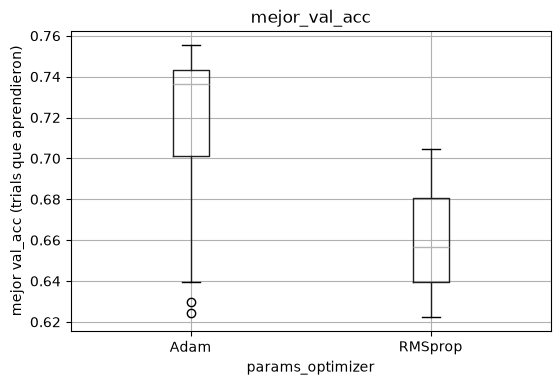

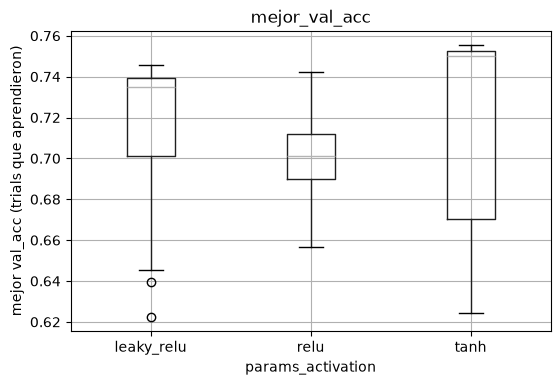

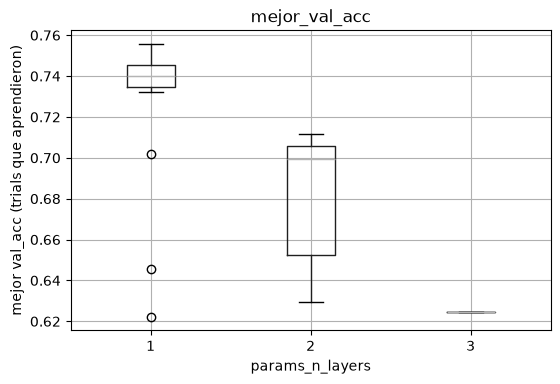

In [19]:
for col in ["params_optimizer", "params_activation", "params_n_layers"]:
    aprendieron.boxplot(column="mejor_val_acc", by=col, figsize=(6, 4))
    plt.suptitle("")
    plt.ylabel("mejor val_acc (trials que aprendieron)")
    plt.show()

### 8.3 Performance vs. tiempo de entrenamiento

Cada punto es un trial. Las cruces son trials podados (su tiempo es menor porque se cortaron antes).

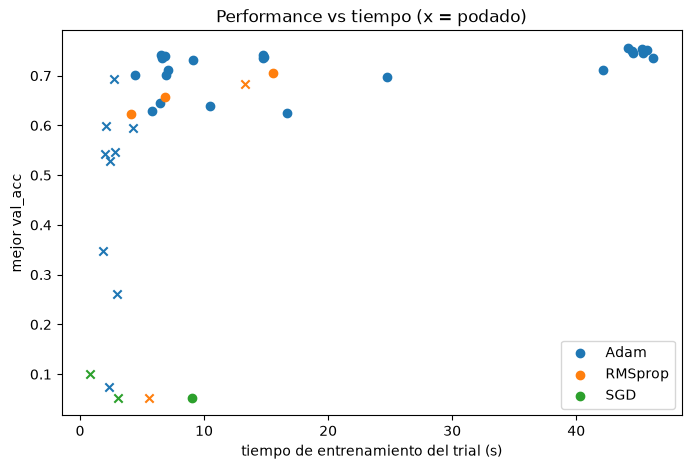

In [20]:
colores = {"Adam": "tab:blue", "RMSprop": "tab:orange", "SGD": "tab:green"}

plt.figure(figsize=(8, 5))
for opt_name, color in colores.items():
    c = completos[completos["params_optimizer"] == opt_name]
    p = podados[podados["params_optimizer"] == opt_name]
    plt.scatter(c["tiempo_train_s"], c["mejor_val_acc"], color=color, label=opt_name)
    plt.scatter(p["tiempo_train_s"], p["mejor_val_acc"], color=color, marker="x")
plt.xlabel("tiempo de entrenamiento del trial (s)")
plt.ylabel("mejor val_acc")
plt.title("Performance vs tiempo (x = podado)")
plt.legend()
plt.show()

In [21]:
# Importancia de cada hiperparámetro según Optuna
vis.plot_param_importances(study).show()

c:\REDES NEURONALES\TP2_MLP_FernandezSanJuan\.venv\Lib\site-packages\optuna\importance\_ped_anova\evaluator.py:353: UserWarning: Some regimes for parameter `sgd_momentum` have less than 2 trials. The importance of the parameter may be inaccurate.
  optuna_warn(


### 8.4 Comparación controlada de optimizadores y activaciones

Optuna se concentró rápido en Adam porque era lo que mejor venía andando: de los 40 trials, 32 usaron Adam, 5 RMSprop y solo 3 SGD. En activaciones probó sobre todo leaky_relu (20 trials), y sigmoid apareció solo 4 veces (las 4 podadas). Además, cada trial cambia muchos hiperparámetros a la vez, así que los resultados quedan mezclados.

Por ejemplo, el único trial completo que no aprendió (el trial 2, val_acc 0,054) usaba al mismo tiempo SGD, ReLU y 3 capas ocultas, y no se puede saber cuál de esas cosas fue el problema. Por eso se tomó la mejor configuración encontrada (preprocesamiento y arquitectura) y se cambió una sola cosa por vez: primero el optimizador y después la activación, dejando todo lo demás fijo (lr 0,001, batch 128, 10 épocas, misma semilla).


Además del learning rate y el optimizador, la **escala de la entrada** también explica por qué SGD con lr = 0,001 no aprende. Con TF-IDF casi todos los valores de entrada son 0 y los que no lo son resultan chicos, porque cada documento está normalizado a norma 1 y reparte ese valor entre todas sus palabras. El gradiente de cada peso de la primera capa es proporcional al valor de la entrada correspondiente, así que esos gradientes son chicos, y además cada peso recibe gradiente solo en los pocos documentos donde aparece su palabra. Con SGD, el paso es lr × gradiente, así que con lr = 0,001 y gradientes chicos los pesos casi no se mueven. Adam y RMSprop dividen por el tamaño típico del gradiente de cada peso, y por eso no sufren este problema. Los valores de entrada se imprimen al principio de la celda.

In [22]:
bp = study.best_params
X_tr, X_val, y_tr, y_val = get_train_val(bp["remove_stopwords"], bp["normalization"],
                                         (1, 1) if bp["ngram_range"] == "1gram" else (1, 2),
                                         bp["max_features"], bp["min_df"])
train_loader_c = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=128, shuffle=True)
val_loader_c = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=128, shuffle=False)
hidden_c = [bp[f"n_units_l{i}"] for i in range(bp["n_layers"])]

# Escala de la entrada (ver texto de arriba)
pct_ceros = 100 * (1 - X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1]))
print(f"Entrada TF-IDF: {pct_ceros:.1f}% de ceros | valores no nulos: media {X_tr.data.mean():.4f}, "
      f"mediana {np.median(X_tr.data):.4f}, máximo {X_tr.data.max():.4f}\n")


def correr(nombre, activation, opt_name, lr, momentum=0.0):
    torch.manual_seed(SEED)
    m = MLP(X_tr.shape[1], hidden_c, NUM_CLASSES, activation)
    if opt_name == "Adam":
        opt = optim.Adam(m.parameters(), lr=lr)
    elif opt_name == "RMSprop":
        opt = optim.RMSprop(m.parameters(), lr=lr)
    else:
        opt = optim.SGD(m.parameters(), lr=lr, momentum=momentum)
    h = train_model(m, train_loader_c, val_loader_c, opt, epochs=10, run_name=nombre, verbose=False)
    return {"experimento": nombre, "mejor_val_acc": max(h["val_acc"]),
            "mejor_epoca": int(np.argmax(h["val_acc"])) + 1,
            "train_acc_final": h["train_acc"][-1], "seg_por_epoca": np.mean(h["epoch_time"])}


mlflow.end_run()
act = bp["activation"]
filas_opt = [
    correr(f"Adam lr=0.001 ({act})", act, "Adam", 1e-3),
    correr(f"RMSprop lr=0.001 ({act})", act, "RMSprop", 1e-3),
    correr(f"SGD lr=0.001 momentum=0.9 ({act})", act, "SGD", 1e-3, 0.9),
    correr(f"SGD lr=0.1 sin momentum ({act})", act, "SGD", 0.1, 0.0),
    correr(f"SGD lr=0.1 momentum=0.9 ({act})", act, "SGD", 0.1, 0.9),
]
print("Optimizadores:")
display(pd.DataFrame(filas_opt).round(4))

filas_act = [correr(f"Adam lr=0.001 + {a}", a, "Adam", 1e-3) for a in ["relu", "leaky_relu", "tanh", "sigmoid"]]
print("Activaciones:")
display(pd.DataFrame(filas_act).round(4))

Entrada TF-IDF: 99.5% de ceros | valores no nulos: media 0.0986, mediana 0.0731, máximo 1.0000

Optimizadores:


,experimento,mejor_val_acc,mejor_epoca,train_acc_final,seg_por_epoca
0,Adam lr=0.001 (tanh),0.7548,5,0.9719,1.7811
1,RMSprop lr=0.001 (tanh),0.7512,3,0.9723,1.4048
2,SGD lr=0.001 momentum=0.9 (tanh),0.0570,1,0.0559,1.3924
3,SGD lr=0.1 sin momentum (tanh),0.4688,10,0.3677,1.0465
4,SGD lr=0.1 momentum=0.9 (tanh),0.6907,9,0.7943,1.3394


Activaciones:


,experimento,mejor_val_acc,mejor_epoca,train_acc_final,seg_por_epoca
0,Adam lr=0.001 + relu,0.7517,7,0.9708,1.6220
1,Adam lr=0.001 + leaky_relu,0.7521,6,0.9706,1.6210
2,Adam lr=0.001 + tanh,0.7548,5,0.9719,1.6199
3,Adam lr=0.001 + sigmoid,0.7327,10,0.8376,1.6238


## **9. Entrenamiento final y evaluación en test**


- Se usa el mismo split de la búsqueda: 80% del train para entrenar y 20% para validación.
- Se entrena hasta 30 épocas con **early stopping**: si la val_acc no mejora durante 3 épocas seguidas se corta, y el modelo se queda con los pesos de la **mejor época según validación**.
- El test se usa **una sola vez** por modelo, al final.
- Se repite con **3 semillas** (pesos iniciales y orden de los batches) y se reporta media ± desvío.

La misma función `entrenar_final` se usa después para la softmax (sección 11), así los dos modelos se entrenan exactamente igual.

In [23]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
BEST_HIDDEN = [best[f"n_units_l{i}"] for i in range(best["n_layers"])]
BEST_ACTIVATION = best["activation"]
BEST_OPTIMIZER = best["optimizer"]
PREPRO_MLP = dict(remove_stopwords=BEST_REMOVE_SW, normalization=BEST_NORM, ngram_range=BEST_NGRAM,
                  max_features=BEST_MAX_FEATURES, min_df=BEST_MIN_DF)

SEMILLAS_FINAL = [42, 43, 44]
EPOCHS_MAX_FINAL = 30
PATIENCE = 3


def predecir(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(device))
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(yb.numpy())
    return np.array(all_labels), np.array(all_preds)


def datos_finales(remove_stopwords, normalization, ngram_range, max_features, min_df):
    # Mismo split train / validación que en la búsqueda; el TF-IDF se ajusta solo con train
    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, y_tr, y_val = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )
    vec = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    return (vec.fit_transform(tr_texts), vec.transform(val_texts), vec.transform(test_texts),
            y_tr, y_val, newsgroups_test.target)


def entrenar_final(nombre, prepro, batch_size, construir):
    # construir(input_dim) devuelve (modelo, optimizador)
    X_tr, X_val, X_te, y_tr, y_val, y_te = datos_finales(**prepro)
    train_ds = to_tensor_dataset(X_tr, y_tr)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=512)
    test_loader = DataLoader(to_tensor_dataset(X_te, y_te), batch_size=512)
    filas, salidas = [], []
    for s in SEMILLAS_FINAL:
        torch.manual_seed(s)
        modelo, opt = construir(X_tr.shape[1])
        with mlflow.start_run(run_name=f"{nombre}_semilla{s}"):
            mlflow.log_params({"semilla": s, "batch_size": batch_size, **{k: str(v) for k, v in prepro.items()}})
            h = train_model(modelo, DataLoader(train_ds, batch_size=batch_size, shuffle=True), val_loader, opt,
                            EPOCHS_MAX_FINAL, run_name=f"{nombre}_s{s}", verbose=False, patience=PATIENCE)
        y_true, y_pred = predecir(modelo, test_loader)  # único uso del test
        filas.append({"modelo": nombre, "semilla": s, "épocas": len(h["val_acc"]), "mejor_epoca": h["mejor_epoca"],
                      "val_acc": max(h["val_acc"]), "test_acc": accuracy_score(y_true, y_pred),
                      "f1_macro": f1_score(y_true, y_pred, average="macro"),
                      "seg_por_epoca": np.mean(h["epoch_time"]), "tiempo_total_s": sum(h["epoch_time"]),
                      "n_params": contar_parametros(modelo)})
        salidas.append({"modelo": modelo, "hist": h, "y_true": y_true, "y_pred": y_pred})
        print(f"{nombre} semilla {s}: mejor época {h['mejor_epoca']} | val_acc {filas[-1]['val_acc']:.4f} | "
              f"test_acc {filas[-1]['test_acc']:.4f}")
    return pd.DataFrame(filas), salidas


def construir_mlp(input_dim):
    m = MLP(input_dim, BEST_HIDDEN, NUM_CLASSES, BEST_ACTIVATION)
    return m, crear_optimizador(m, BEST_OPTIMIZER, BEST_LR, best)


print("Arquitectura:", BEST_HIDDEN, BEST_ACTIVATION, "| Optimizador:", BEST_OPTIMIZER, "| lr:", BEST_LR)
mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups_final")
final_mlp, salidas_mlp = entrenar_final("MLP", PREPRO_MLP, BEST_BATCH_SIZE, construir_mlp)
display(final_mlp.round(4))
print(f"\nMLP: test_acc {final_mlp['test_acc'].mean():.4f} ± {final_mlp['test_acc'].std():.4f} (media ± desvío, 3 semillas)")

2026/11/21 02:46:16 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups_final' does not exist. Creating a new experiment.


Arquitectura: [256] tanh | Optimizador: Adam | lr: 0.00025210075309610257
MLP semilla 42: mejor época 8 | val_acc 0.7530 | test_acc 0.6847
MLP semilla 43: mejor época 7 | val_acc 0.7525 | test_acc 0.6892
MLP semilla 44: mejor época 7 | val_acc 0.7530 | test_acc 0.6857


,modelo,semilla,épocas,mejor_epoca,val_acc,test_acc,f1_macro,seg_por_epoca,tiempo_total_s,n_params
0,MLP,42,11,8,0.7530,0.6847,0.6748,4.3264,47.5902,2565396
1,MLP,43,10,7,0.7525,0.6892,0.6781,4.7003,47.0026,2565396
2,MLP,44,10,7,0.7530,0.6857,0.6748,4.3716,43.7160,2565396



MLP: test_acc 0.6865 ± 0.0024 (media ± desvío, 3 semillas)


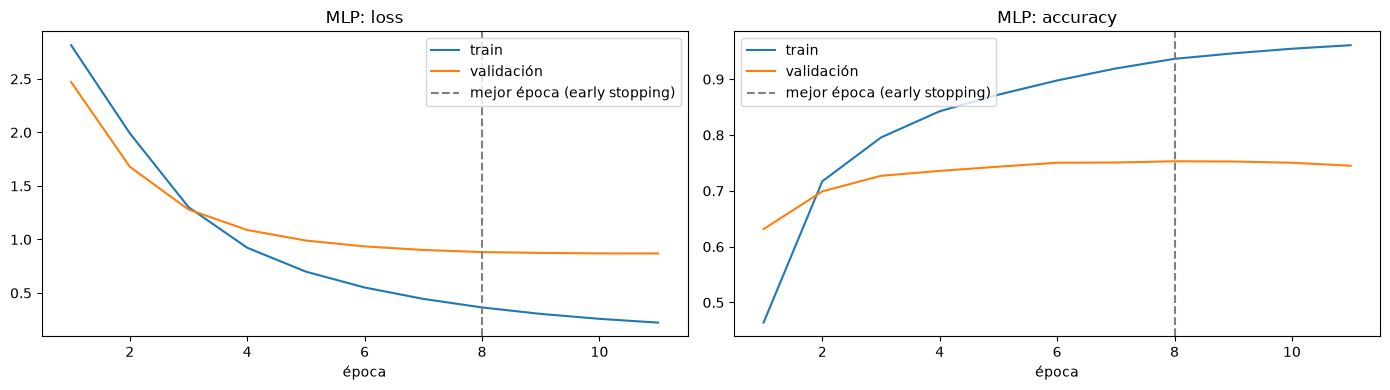

In [24]:
# Curvas de la primera semilla: train vs validación (el test no se mira durante el entrenamiento)
h = salidas_mlp[0]["hist"]
ep = range(1, len(h["val_acc"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ep, h["train_loss"], label="train")
axes[0].plot(ep, h["val_loss"], label="validación")
axes[0].set_title("MLP: loss")
axes[1].plot(ep, h["train_acc"], label="train")
axes[1].plot(ep, h["val_acc"], label="validación")
axes[1].set_title("MLP: accuracy")
for ax in axes:
    ax.axvline(h["mejor_epoca"], color="gray", linestyle="--", label="mejor época (early stopping)")
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

In [25]:
# Reporte por clase del modelo de la primera semilla
y_true, y_pred_mlp = salidas_mlp[0]["y_true"], salidas_mlp[0]["y_pred"]
test_acc_mlp = accuracy_score(y_true, y_pred_mlp)
print(f"Accuracy en test (MLP, semilla 42): {test_acc_mlp:.4f}\n")
print(classification_report(y_true, y_pred_mlp, target_names=class_names))

Accuracy en test (MLP, semilla 42): 0.6847

                          precision    recall  f1-score   support

             alt.atheism       0.47      0.51      0.49       319
           comp.graphics       0.61      0.68      0.64       389
 comp.os.ms-windows.misc       0.62      0.62      0.62       394
comp.sys.ibm.pc.hardware       0.66      0.60      0.63       392
   comp.sys.mac.hardware       0.71      0.71      0.71       385
          comp.windows.x       0.81      0.66      0.73       395
            misc.forsale       0.74      0.79      0.77       390
               rec.autos       0.48      0.78      0.59       396
         rec.motorcycles       0.77      0.71      0.74       398
      rec.sport.baseball       0.88      0.81      0.85       397
        rec.sport.hockey       0.91      0.88      0.90       399
               sci.crypt       0.83      0.71      0.76       396
         sci.electronics       0.60      0.57      0.58       393
                 sci.med       

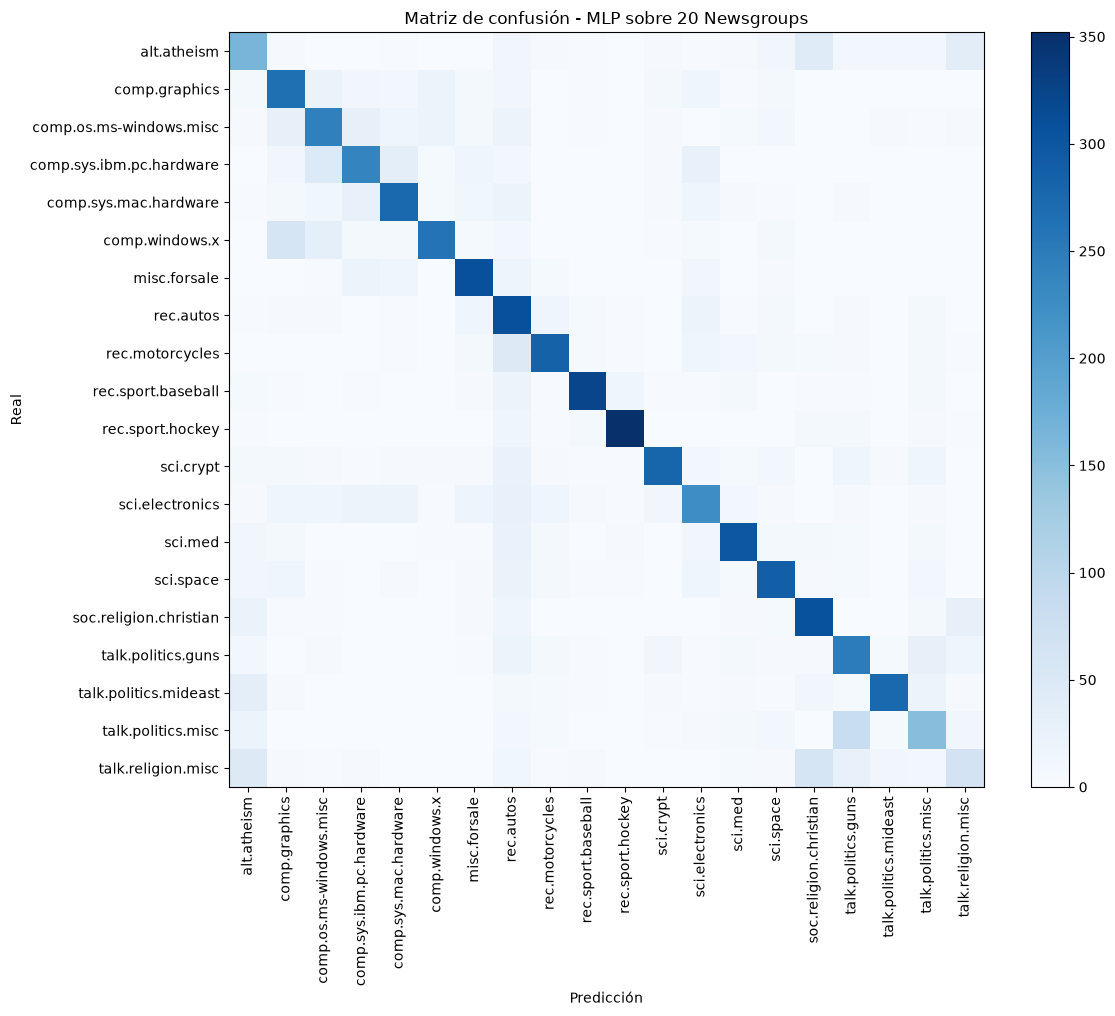

In [26]:
cm = confusion_matrix(y_true, y_pred_mlp)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()

## 10. **Experimento de overfitting**

Buscamos una cantidad de capas y neuronas con la que el modelo quede claramente **overfiteado**: la loss de train sigue bajando (y la accuracy de train llega a su techo) mientras la loss de validación deja de bajar y empieza a subir.

Para aislar el efecto de la capacidad de la red, dejamos fijo todo lo demás (preprocesamiento del mejor trial, Adam con lr=1e-3, ReLU, batch 64, sin ninguna regularización) y variamos solo la arquitectura, de chica a muy grande. Entrenamos más épocas que en la búsqueda y usamos el mismo split train/validación de Optuna (no el test).

En términos de sesgo-varianza: al aumentar la capacidad de la red baja el error de train (menos sesgo), pero el modelo empieza a memorizar el train y generaliza peor (más varianza). Para corregirlo se podría usar alguna de las técnicas de regularización vistas en clase (dropout, weight decay o early stopping), pero acá no las usamos a propósito.

In [27]:
CONFIGS_OVERFIT = {
    "1x64": [64],
    "2x256": [256, 256],
    "3x1024": [1024, 1024, 1024],
}
EPOCHS_OVERFIT = 25

X_tr, X_val, tr_labels, val_labels = get_train_val(BEST_REMOVE_SW, BEST_NORM, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF)
train_loader_of = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=64, shuffle=True)
val_loader_of = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=64, shuffle=False)

mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups_overfitting")
historias_of = {}
n_params_of = {}
for nombre, hidden in CONFIGS_OVERFIT.items():
    torch.manual_seed(SEED)
    m = MLP(input_dim=X_tr.shape[1], hidden_sizes=hidden, num_classes=NUM_CLASSES, activation="relu")
    n_params_of[nombre] = contar_parametros(m)
    opt = optim.Adam(m.parameters(), lr=1e-3)
    writer = SummaryWriter(log_dir=f"runs/overfit_{nombre}")
    with mlflow.start_run(run_name=f"overfit_{nombre}"):
        mlflow.log_params({"hidden_sizes": str(hidden), "lr": 1e-3, "optimizer": "Adam", "epochs": EPOCHS_OVERFIT})
        historias_of[nombre] = train_model(m, train_loader_of, val_loader_of, opt, epochs=EPOCHS_OVERFIT,
                                           writer=writer, run_name=nombre)
    writer.close()

2026/11/21 02:48:42 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups_overfitting' does not exist. Creating a new experiment.


[1x64] Epoch 1/25 - train_loss: 2.8118 train_acc: 0.3827 - val_loss: 2.4549 val_acc: 0.6169 - 1.0s
[1x64] Epoch 2/25 - train_loss: 1.9446 train_acc: 0.7217 - val_loss: 1.6235 val_acc: 0.7057 - 0.9s
[1x64] Epoch 3/25 - train_loss: 1.2166 train_acc: 0.8091 - val_loss: 1.2250 val_acc: 0.7251 - 1.0s
[1x64] Epoch 4/25 - train_loss: 0.8413 train_acc: 0.8503 - val_loss: 1.0546 val_acc: 0.7397 - 1.0s
[1x64] Epoch 5/25 - train_loss: 0.6305 train_acc: 0.8843 - val_loss: 0.9681 val_acc: 0.7446 - 1.0s
[1x64] Epoch 6/25 - train_loss: 0.4914 train_acc: 0.9121 - val_loss: 0.9223 val_acc: 0.7499 - 0.9s
[1x64] Epoch 7/25 - train_loss: 0.3929 train_acc: 0.9315 - val_loss: 0.8991 val_acc: 0.7530 - 0.9s
[1x64] Epoch 8/25 - train_loss: 0.3208 train_acc: 0.9448 - val_loss: 0.8833 val_acc: 0.7486 - 0.9s
[1x64] Epoch 9/25 - train_loss: 0.2669 train_acc: 0.9547 - val_loss: 0.8768 val_acc: 0.7481 - 0.9s
[1x64] Epoch 10/25 - train_loss: 0.2267 train_acc: 0.9610 - val_loss: 0.8783 val_acc: 0.7490 - 0.9s
[1x64] Ep

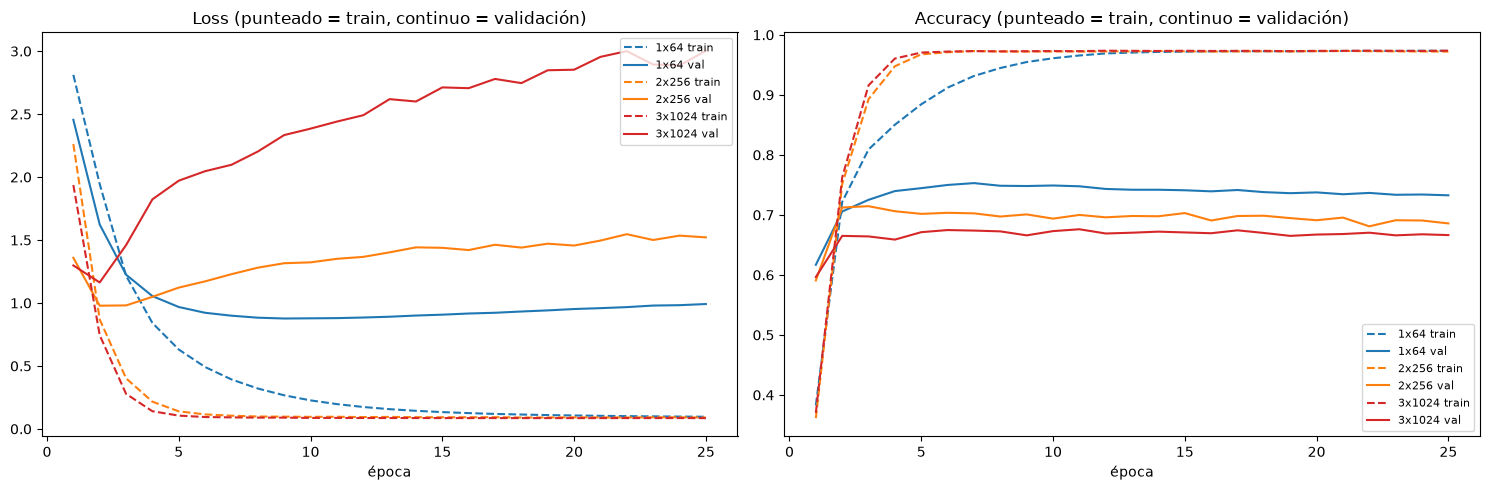

,config,n_params,train_acc_final,val_acc_final,mejor_val_acc,epoca_min_val_loss,val_loss_min,val_loss_final,brecha_acc_final,seg_por_epoca
0,1x64,641364,0.9734,0.7327,0.7530,9,0.8768,0.9917,0.2407,0.9190
1,2x256,2631188,0.9722,0.6858,0.7145,2,0.9786,1.5212,0.2863,2.6873
2,3x1024,12360724,0.9736,0.6664,0.6761,2,1.1631,3.0035,0.3072,10.6498


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epocas = range(1, EPOCHS_OVERFIT + 1)
for (nombre, h), color in zip(historias_of.items(), ["tab:blue", "tab:orange", "tab:red"]):
    axes[0].plot(epocas, h["train_loss"], "--", color=color, label=f"{nombre} train")
    axes[0].plot(epocas, h["val_loss"], "-", color=color, label=f"{nombre} val")
    axes[1].plot(epocas, h["train_acc"], "--", color=color, label=f"{nombre} train")
    axes[1].plot(epocas, h["val_acc"], "-", color=color, label=f"{nombre} val")
axes[0].set_title("Loss (punteado = train, continuo = validación)")
axes[1].set_title("Accuracy (punteado = train, continuo = validación)")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

filas = []
for nombre, h in historias_of.items():
    filas.append({
        "config": nombre,
        "n_params": n_params_of[nombre],
        "train_acc_final": h["train_acc"][-1],
        "val_acc_final": h["val_acc"][-1],
        "mejor_val_acc": max(h["val_acc"]),
        "epoca_min_val_loss": int(np.argmin(h["val_loss"])) + 1,
        "val_loss_min": min(h["val_loss"]),
        "val_loss_final": h["val_loss"][-1],
        "brecha_acc_final": h["train_acc"][-1] - h["val_acc"][-1],
        "seg_por_epoca": np.mean(h["epoch_time"]),
    })
tabla_overfit = pd.DataFrame(filas).round(4)
display(tabla_overfit)

## **11. Comparación con Regresión Softmax (controlada)**


Los dos modelos tienen:
- **El mismo presupuesto de búsqueda:** la softmax tiene su propia búsqueda con Optuna, con el mismo espacio de preprocesamiento, lr y batch size, la misma cantidad de trials (`N_TRIALS`) y épocas (`EPOCHS_BUSQUEDA`), el mismo sampler con semilla y el mismo pruner.
- **El mismo protocolo final:** la misma función `entrenar_final` (mismo split, early stopping sobre validación con patience 3, 3 semillas, test una sola vez).

Lo único distinto es el modelo y los hiperparámetros propios de cada uno (la softmax no tiene capas ni activación, y usa Adam como en el TP1).

In [29]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)


def objective_softmax(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    X_tr, X_val, tr_labels, val_labels = get_train_val(
        remove_stopwords, normalization, ngram_range_tuple, max_features, min_df
    )
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)
    model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    with mlflow.start_run(run_name=f"softmax_trial_{trial.number}"):
        mlflow.log_params(trial.params)
        h = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS_BUSQUEDA,
                        run_name=f"softmax_trial_{trial.number}", trial=trial, verbose=False)
    return max(h["val_acc"])


mlflow.end_run()
mlflow.set_experiment("softmax_20newsgroups_busqueda")
study_sm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                               pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
                               study_name="softmax_tng")
t0 = time.perf_counter()
study_sm.optimize(objective_softmax, n_trials=N_TRIALS)
tiempo_busqueda_sm = time.perf_counter() - t0
print(f"\nSoftmax: {N_TRIALS} trials en {tiempo_busqueda_sm / 60:.1f} min")
print("Mejores hiperparámetros:", study_sm.best_params)
print(f"Mejor val_acc de la búsqueda: {study_sm.best_value:.4f}")

bps = study_sm.best_params
PREPRO_SM = dict(remove_stopwords=bps["remove_stopwords"], normalization=bps["normalization"],
                 ngram_range=(1, 1) if bps["ngram_range"] == "1gram" else (1, 2),
                 max_features=bps["max_features"], min_df=bps["min_df"])


def construir_softmax(input_dim):
    m = SoftmaxRegression(input_dim, NUM_CLASSES)
    return m, optim.Adam(m.parameters(), lr=bps["lr"])


mlflow.set_experiment("mlp_20newsgroups_final")
final_sm, salidas_sm = entrenar_final("Softmax", PREPRO_SM, bps["batch_size"], construir_softmax)
display(final_sm.round(4))

2026/11/21 02:54:44 INFO mlflow.tracking.fluent: Experiment with name 'softmax_20newsgroups_busqueda' does not exist. Creating a new experiment.
[I 2026-11-21 02:54:44,858] A new study created in memory with name: softmax_tng
[I 2026-11-21 02:54:47,923] Trial 0 finished with value: 0.5647370746796289 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0004335281794951569, 'batch_size': 128}. Best is trial 0 with value: 0.5647370746796289.
[I 2026-11-21 02:54:58,524] Trial 1 finished with value: 0.6478126380910296 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.006647135865318032, 'batch_size': 128}. Best is trial 1 with value: 0.6478126380910296.
[I 2026-11-21 02:55:07,323] Trial 2 finished with value: 0.7211665930181176 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram'


Softmax: 40 trials en 3.8 min
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.027008520672294405, 'batch_size': 128}
Mejor val_acc de la búsqueda: 0.7433
Softmax semilla 42: mejor época 3 | val_acc 0.7397 | test_acc 0.6677
Softmax semilla 43: mejor época 3 | val_acc 0.7433 | test_acc 0.6698
Softmax semilla 44: mejor época 4 | val_acc 0.7402 | test_acc 0.6640


,modelo,semilla,épocas,mejor_epoca,val_acc,test_acc,f1_macro,seg_por_epoca,tiempo_total_s,n_params
0,Softmax,42,6,3,0.7397,0.6677,0.6550,0.4780,2.8683,200020
1,Softmax,43,6,3,0.7433,0.6698,0.6567,0.5036,3.0217,200020
2,Softmax,44,7,4,0.7402,0.6640,0.6534,0.4899,3.4296,200020


,val_acc,test_acc,test_acc_desvio,f1_macro,mejor_epoca,seg_por_epoca,tiempo_total_s,n_params
modelo,,,,,,,,
Softmax,0.7411,0.6672,0.0030,0.6550,3.3333,0.4905,3.1065,200020
MLP,0.7528,0.6865,0.0024,0.6759,7.3333,4.4661,46.1029,2565396


Búsqueda (mismo presupuesto): softmax mejor val_acc 0.7433 | MLP mejor val_acc 0.7556


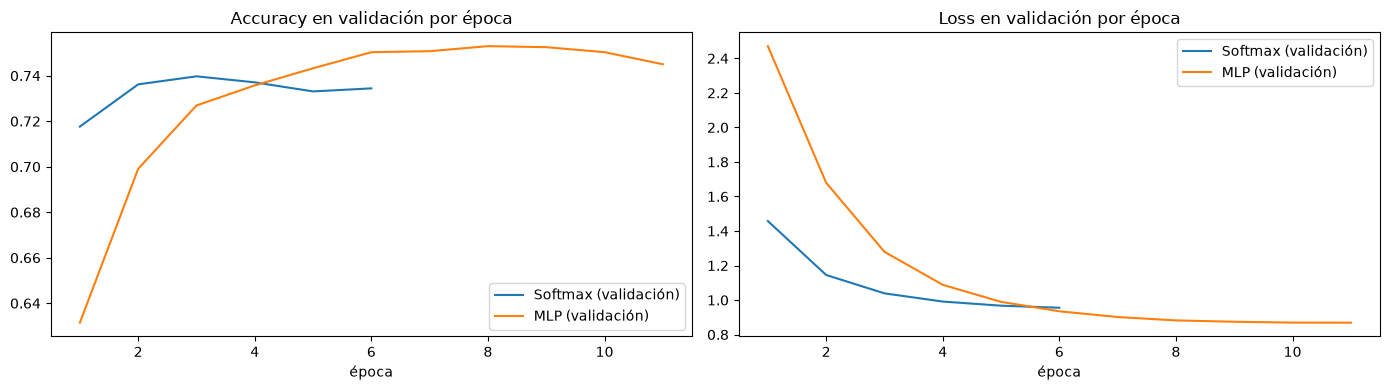

In [30]:
comparacion = pd.concat([final_sm, final_mlp]).groupby("modelo").agg(
    val_acc=("val_acc", "mean"), test_acc=("test_acc", "mean"), test_acc_desvio=("test_acc", "std"),
    f1_macro=("f1_macro", "mean"), mejor_epoca=("mejor_epoca", "mean"),
    seg_por_epoca=("seg_por_epoca", "mean"), tiempo_total_s=("tiempo_total_s", "mean"),
    n_params=("n_params", "first"),
).loc[["Softmax", "MLP"]]
display(comparacion.round(4))
print(f"Búsqueda (mismo presupuesto): softmax mejor val_acc {study_sm.best_value:.4f} | MLP mejor val_acc {study.best_value:.4f}")

# Curvas de validación de la primera semilla de cada modelo
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for nombre, salidas in [("Softmax", salidas_sm), ("MLP", salidas_mlp)]:
    h = salidas[0]["hist"]
    ep = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["val_acc"], label=f"{nombre} (validación)")
    axes[1].plot(ep, h["val_loss"], label=f"{nombre} (validación)")
axes[0].set_title("Accuracy en validación por época")
axes[1].set_title("Loss en validación por época")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

In [31]:
# F1 por clase (primera semilla de cada modelo): ¿en qué categorías mejora o empeora el MLP?
y_pred_sm = salidas_sm[0]["y_pred"]
f1_por_clase = pd.DataFrame({
    "softmax": f1_score(y_true, y_pred_sm, average=None),
    "mlp": f1_score(y_true, y_pred_mlp, average=None),
}, index=class_names)
f1_por_clase["diferencia"] = f1_por_clase["mlp"] - f1_por_clase["softmax"]
display(f1_por_clase.sort_values("diferencia").round(3))

,softmax,mlp,diferencia
rec.autos,0.708,0.594,-0.114
sci.electronics,0.598,0.584,-0.014
soc.religion.christian,0.718,0.725,0.007
alt.atheism,0.483,0.490,0.008
rec.sport.hockey,0.886,0.896,0.009
talk.politics.guns,0.623,0.633,0.010
talk.religion.misc,0.295,0.305,0.011
sci.space,0.728,0.740,0.012
comp.graphics,0.631,0.643,0.013
comp.sys.ibm.pc.hardware,0.618,0.633,0.015


## **12. Conclusiones**

Todos los números de esta sección salen de las salidas de esta corrida (en CPU).

### **Búsqueda de hiperparámetros**

**Conclusión: el mejor modelo fue simple (una sola capa oculta) y todos los mejores trials usaron Adam.**

- Los 40 trials tardaron 11,8 minutos: 27 terminaron completos, 13 se podaron y uno de los completos no aprendió (el trial 2, con SGD).
- El mejor fue el trial 32, con val_acc 0,7556 en la época 8:
    - Preprocesamiento: sin stopwords, stemming, unigramas, 10.000 palabras y min_df 2.
    - Red: una capa oculta de 256 neuronas con tanh.
    - Entrenamiento: Adam (lr = 0,00025, beta1 = 0,84, beta2 = 0,9995) y batch 32.
- Los 10 mejores trials comparten Adam, una sola capa oculta y 10.000 palabras. Lo que cambia entre ellos es la activación (tanh, leaky_relu y relu) y el ancho de la capa (64 o 256).


### **Importancia de hiperparámetros**

**Conclusión: según Optuna, beta1 es lo que más influye, seguido del learning rate.**

- Importancias: beta1 0,44; learning rate 0,26; n-gramas 0,08; 1 − beta2 0,06; activación 0,05; capas 0,03; neuronas 0,03; min_df 0,02; batch size 0,01; optimizador 0,01; normalización 0,01; max_features y stopwords, menos de 0,01.
- Hay que tener cuidado: la importancia mide cuánto varió la val_acc entre los trials probados, no cuánto importa cada hiperparámetro en general. De los 27 trials completos, 23 aprendieron con Adam, 3 con RMSprop y el único completo con SGD no aprendió; por eso el optimizador tuvo poca variación útil. Además, son pocos trials completos, así que los valores son ruidosos.

### **Optimizadores**

**Conclusión: Adam y RMSprop rinden parecido; SGD necesita un learning rate 100 veces mayor y momentum para acercarse, por la escala chica de la entrada.**

- En la comparación controlada (sección 8.4), con lr 0,001:
    - Adam: 0,7548 (mejor época 5).
    - RMSprop: 0,7512 (mejor época 3).
    - SGD con momentum 0,9: 0,0570, cerca de adivinar al azar. La accuracy de train terminó en 0,0559.
- Subiendo el lr de SGD 100 veces (lr 0,1):
    - Sin momentum: 0,4688, y seguía mejorando en la época 10.
    - Con momentum 0,9: 0,6907, todavía por debajo de Adam y RMSprop.
- Esto se da ya que el 99,5 % de los valores del TF-IDF son 0, y los que no lo son tienen media 0,0986. Los gradientes de la primera capa son chicos. SGD da pasos de lr*gradiente, así que con gradientes chicos casi no se mueve. Adam y RMSprop ajustan el paso de cada peso según el tamaño de su gradiente, y compensan. El momentum ayuda a SGD porque acumula gradientes y les da inercia a los pasos.
- Hay que tener cuidado ya que en la búsqueda solo 3 trials completos aprendieron con RMSprop, muy pocos para compararlos con Adam (mediana 0,7362 en 23 trials). Por eso vale más la comparación controlada, donde rinden parecido.

### **Activaciones**

**Conclusión: tanh, leaky_relu y relu tienen poca diferencia mientras que sigmoid aprende más lento.**

- Con Adam y lr 0,001: tanh 0,7548, leaky_relu 0,7521, relu 0,7517 y sigmoid 0,7327.
- Las tres primeras quedan a menos de medio punto. Esa diferencia es del orden del ruido entre semillas de la sección 9 (desvío 0,0024), así que no se puede decir que una sea mejor.
- Sigmoid todavía estaba aprendiendo al final: su mejor época fue la 10 (la última) y su accuracy de train llegó solo a 0,8376, contra ~0,97 de las demás.
- Esto se da ya qye la derivada de la sigmoide es como máximo 0,25 y se achica cuando la neurona se satura, así que los gradientes llegan más chicos.
- En la búsqueda, los 4 trials con sigmoid se podaron en la época 3. Es probable que el pruner la haya castigado por arrancar lento y no necesariamente porque termine peor.

### **Cantidad de capas y neuronas**

**Conclusión: una sola capa oculta anduvo mejor, y pasar de 64 a 256 neuronas ganó poco a un costo alto.**

- Mediana de val_acc: 0,7402 con 1 capa (17 trials), 0,6995 con 2 (8 trials) y 0,6244 con 3 (un solo trial que aprendió).
- Con TF-IDF de 10.000 palabras y ~9.000 documentos de entrenamiento, una red más grande memoriza el train en vez de generalizar mejor. Coincide con el experimento de overfitting (sección 10).
- En la búsqueda las capas cambian junto con otros hiperparámetros, así que esto solo no lo prueba.
- Ancho, con batch 32: la mejor capa de 256 neuronas (0,7556) le ganó por poco más de un punto a la mejor de 64 (0,7411, trial 19). A cambio, tiene 4 veces más parámetros (2.565.396 contra 641.364) y tarda unas 3 veces más por época (4,42 s contra 1,48 s).

### **Tiempos**

**Conclusión: el tiempo depende del tamaño de la red y del batch size. No depende mucho del optimizador ni de la activación. Los últimos puntos de accuracy son los más caros.**

- En la comparación controlada, las variantes de optimizador y activación tardaron entre 1,0 y 1,8 s por época.
- Promedio por época en los trials: batch 32, 2,78 s; batch 64, 0,93 s; batch 128, 0,68 s. Batch 32 es el más lento, en parte porque tiene cuatro veces más pasos por época que batch 128.
- Tamaño de la red (experimento de overfitting): 0,9 s por época con 1×64, 2,7 s con 2×256 y 10,6 s con 3×1024.
- El mejor trial (capa de 256 y batch 32) tardó unos 44 s en sus 10 épocas. Trials con 64 neuronas llegaron a 0,7424 en unos 6,5 s (batch 128) y a 0,7411 en unos 14,8 s (batch 32).

### **Pruning**

**Conclusión: el pruning ahorró unos 2,7 minutos, pero castiga a las configuraciones que arrancan lento.**

- Se podaron 13 de los 40 trials, todos en la época 3, la primera en la que el pruner puede cortar.
- Se entrenaron 309 de las 400 épocas posibles. Ahorro estimado: unos 2,7 minutos sobre 9,9 de entrenamiento (sin pruning habrían sido unos 12,6).
- Cortar tan temprano castiga a lo que arranca lento, como sigmoid o SGD, aunque pueda terminar bien. Dos trials podados llegaron a 0,68-0,69 en su último paso, pero no se puede saber hasta dónde habrían llegado.

### **Overfitting**

**Conclusión: las tres redes sobreajustan, y cuanto más grande la red, antes y más fuerte. La más grande es la que peor generaliza y la más lenta.**

Las tres redes usan ReLU, Adam con lr 0,001, batch 64 y nada de regularización:

| Red | Parámetros | Val loss mínima | Val loss final | Mejor val_acc |
|---|---:|---:|---:|---:|
| 1×64 | 641.364 | 0,8768 (época 9) | 0,9917 | 0,7530 |
| 2×256 | 2,6 millones | 0,9786 (época 2) | 1,5212 | 0,7145 |
| 3×1024 | 12,4 millones | 1,1631 (época 2) | 3,0035 | 0,6761 |

- La val_acc de la red chica llega a 0,7530 y termina en 0,7327. En la grande, la loss de validación termina más del doble de su mínimo.
- La señal de overfitting es que la loss de train sigue bajando mientras la de validación sube. El modelo se vuelve cada vez más confiado en sus predicciones equivocadas.
- La accuracy de train termina entre 0,9722 y 0,9736, y no llega a 1 en ninguna red. Probablemente sea porque hay posts que, después de sacar encabezados, citas y firmas, quedan vacíos o iguales a otros con distinta etiqueta, y esos no se pueden separar aunque esto no fue verificado.
- En la red de 3×1024 la train_acc se mantuvo cerca de 0,973; la val_loss osciló en valores altos y terminó en 3,0035, sin mejorar la generalización (val_acc final 0,6664).
- Por eso conviene usar early stopping incluso con la red chica.

### **Entrenamiento final**

**Conclusión: el MLP final da 0,6865 ± 0,0024 en test. Religión y política siguen siendo las clases más difíciles.**

- Las tres semillas dieron 0,6847, 0,6892 y 0,6857 de accuracy en test: **0,6865 ± 0,0024**, con F1 macro promedio de 0,6759.
- Las mejores épocas fueron 8, 7 y 7; early stopping cortó en las épocas 11, 10 y 10. Cada entrenamiento tardó unos 46 s (4,3-4,7 s por época).
- Curvas: a partir de la época 6, la accuracy de train sigue subiendo (llega a 0,96) mientras la de validación queda estancada en ~0,75.
- Por clase:
    - Las mejores son rec.sport.hockey (F1 0,90) y rec.sport.baseball (0,85).
    - Las peores son talk.religion.misc (0,31; encuentra solo el 25 % de sus documentos), alt.atheism (0,49) y talk.politics.misc (0,51).
- rec.autos funciona como "cajón de sastre": recall 0,78 pero precision 0,48, y en la matriz de confusión su columna recibe documentos de casi todas las clases. En el TP1 ese papel lo cumplía rec.sport.baseball.
- Esto se da posiblemente porque un documento vacío tiene todas sus entradas en 0, y para esa entrada la red siempre da la misma salida, así que todos los documentos vacíos o casi vacíos caen en la misma clase.

### **Comparación con regresión softmax**

**Conclusión: comparando de forma justa, el MLP le gana a la softmax por 1,9 puntos, a cambio de 13 veces más parámetros y 15 veces más tiempo de entrenamiento.**

- Comparación justa: mismo presupuesto de búsqueda y mismo protocolo final. Además, la softmax eligió el mismo preprocesamiento que el MLP, así que los dos ven exactamente la misma entrada.

| | Softmax | MLP |
|---|---:|---:|
| Tiempo de búsqueda | 3,8 min | 11,8 min |
| Mejor val_acc de la búsqueda | 0,7433 | 0,7556 |
| test_acc (3 semillas) | **0,6672 ± 0,0030** | **0,6865 ± 0,0024** |
| F1 macro | 0,6550 | 0,6759 |
| Parámetros | 200.020 | 2.565.396 |
| Tiempo de entrenamiento promedio | 3,1 s | 46,1 s |

- El MLP gana 1,9 puntos de accuracy y 2,1 de F1 macro. La diferencia supera las desviaciones entre semillas, aunque son solo 3 semillas y un único split.
- Curvas: la softmax arranca mucho más alto (0,717 en la época 1) y llega a su mejor valor en la época 3. El MLP arranca en 0,63 y la supera recién desde la época 5.
- Por clase:
    - El MLP mejora 19 de las 20 categorías; las mejoras, salvo una, van de 0,007 a 0,054 de F1.
    - Las de computación mejoran poco (comp.sys.mac.hardware +0,054, comp.windows.x +0,026).
    - Los dos cambios grandes, rec.sport.baseball (+0,180) y rec.autos (−0,114), parecen venir sobre todo de que el "cajón de sastre" pasó de una clase a la otra, no de que el MLP entienda mejor esos temas.
    - Religión y política siguen siendo de las clases más difíciles con los dos modelos.
- Esto confirma la observación de la devolución. La softmax del TP1, con una búsqueda más chica (15 trials de 5 épocas), dio 0,6559 en test. Solo por tener la misma búsqueda que el MLP, la softmax mejora 1,1 puntos; el MLP la supera por 1,9 puntos en esta comparación.

### **Validación contra test**

**Conclusión: el test da 6-7 puntos menos que la validación en los dos modelos.**

- MLP: val_acc promedio 0,7528 y test_acc promedio 0,6865 (6,6 puntos menos).
- Softmax: val_acc promedio 0,7411 y test_acc promedio 0,6672 (7,4 puntos menos).

### Resumen

| Aspecto | Resultado | Conclusión |
|---|---|---|
| Búsqueda (Optuna) | 40 trials en 11,8 min: 27 completos, 13 podados, 1 que no aprendió | Mejor val_acc 0,7556 (trial 32) |
| Mejor configuración | 1 capa de 256, tanh, Adam (lr 0,00025), batch 32, sin stopwords + stemming, unigramas, 10.000 palabras | Los 10 mejores trials usan Adam, 1 capa y 10.000 palabras |
| Optimizadores | Controlado: Adam 0,7548, RMSprop 0,7512, SGD lr 0,001 0,0570, SGD lr 0,1 + momentum 0,6907 | Adam y RMSprop rinden parecido; SGD necesita lr mucho mayor y momentum por la escala chica del TF-IDF |
| Activaciones | Controlado: tanh 0,7548, leaky_relu 0,7521, relu 0,7517, sigmoid 0,7327 | tanh, relu y leaky_relu empatan dentro del ruido; sigmoid aprende más lento |
| Capas ocultas | Mediana 0,7402 (1 capa), 0,6995 (2), 0,6244 (3) | Una capa alcanza; más capas sobreajustan |
| Batch size | 2,78 s/época con batch 32, 0,93 con 64 y 0,68 con 128 | El batch 32 dio los mejores trials, pero es el más lento |
| Pruning | 13 trials podados (todos en la época 3), ~2,7 min ahorrados de 9,9 | Ahorra tiempo pero castiga a las configuraciones que arrancan lento |
| Overfitting | Val loss mínima → final: 0,88 → 0,99 (1×64), 0,98 → 1,52 (2×256), 1,16 → 3,00 (3×1024) | Más capacidad = overfitting antes y más fuerte; 3×1024 tarda 10,6 s/época |
| Test final | MLP 0,6865 ± 0,0024 contra softmax 0,6672 ± 0,0030 (3 semillas) | El MLP gana 1,9 puntos con 13 veces más parámetros y 15 veces más tiempo de entrenamiento |
